| Roll No.| Subject Code | Assignment No. |
|:-------:|:------------:|:--------------:|
| 2650026 | CS69101      | Lab 10         |

# Implementation

Implement a Binomial Min Heap using the left-child, right-sibling representation (key, degree, parent, child, sibling).

Your implementation must support:
1. Construct a Binomial Heap from the given unsorted array by repeated insertion.
2. Insert a new element into the heap.
3. Find the minimum element.
4. Extract-Min operation.
5. Union of two binomial heaps (merge the root lists, then link equal degrees).
6. Delete an arbitrary element.
7. Decrease-Key operation for a specified element.
8. Display the heap after every operation (one line per tree: degree, root, preorder keys).

In [1]:
import os
import sys
from io import TextIOWrapper
from typing import Self, Any, Callable, TypeVar, Generic, Optional
import random
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.pylab import figure

sys.setrecursionlimit(100000) # Fix to avoid RecursionError

os.makedirs("./2650026_lab10_data", exist_ok=True)

prep_arr = [random.randint(1, (i+1)*10) for i in range(100000)] # Random Array of 100000 Elements
# prep_arr.sort() # Sorted Array for Worst Case Scenario
print(prep_arr[:25])
print(len(prep_arr))

# Write the array to a file
f = open("./2650026_lab10_data/input0.txt", "w")
for i in prep_arr:
    f.write(f"{i}, ")
f.write("\n")
f.close()

del prep_arr
del f

iterations = 0
swaps = 0
links = 0
PRINT_DEBUG = False

[10, 4, 11, 6, 12, 60, 43, 28, 52, 85, 82, 103, 107, 103, 139, 51, 140, 118, 102, 152, 80, 124, 101, 45, 49]
100000


In [2]:
def get_random_sample(arr, n):
    if n > len(arr):
        raise ValueError("n cannot exceed the array length")

    start = random.randint(0, len(arr) - n)
    return arr[start : start + n]

In [3]:
class BinomialNode:
    def __init__(self, key: int):
        self.key = key
        self.degree = 0
        self.parent = None
        self.child = None    # leftmost child
        self.sibling = None  # next sibling to the right (or the next root in the root list)

    def __str__(self) -> str:
        return f"Node(key={self.key}, degree={self.degree})"

    def __repr__(self) -> str:
        return self.__str__()

In [4]:
class BinomialHeap:
    def __init__(self, arr: list[int] | None = None):
        self.head = None  # head of the root list (degrees strictly increase from left to right)
        self.size = 0
        if arr is not None:
            self.construct_binomial_heap(arr)

    def construct_binomial_heap(self, arr: list[int]):
        # Repeated insertion
        for value in arr:
            self.binomial_heap_insert(value)

    # Make y the leftmost child of z (y.key >= z.key)
    def _link(self, y: BinomialNode, z: BinomialNode):
        global links
        links += 1
        y.parent = z
        y.sibling = z.child
        z.child = y
        z.degree += 1
        if PRINT_DEBUG:
            print(f"Linked the tree rooted at {y.key} under {z.key}")

    # Merge two root lists into one list sorted by degree
    def _merge_root_lists(self, a: BinomialNode | None, b: BinomialNode | None) -> BinomialNode | None:
        global iterations
        iterations += 1

        if a is None:
            return b
        if b is None:
            return a
        if a.degree <= b.degree:
            a.sibling = self._merge_root_lists(a.sibling, b)
            return a
        b.sibling = self._merge_root_lists(a, b.sibling)
        return b

    # Link trees of equal degree; prev_x is the root before x in the root list
    def _link_roots(self, prev_x: BinomialNode | None, x: BinomialNode):
        global iterations
        iterations += 1

        next_x = x.sibling
        if next_x is None:
            return
        if x.degree != next_x.degree or (next_x.sibling is not None and next_x.sibling.degree == x.degree):
            self._link_roots(x, next_x)  # Case 1 and 2: nothing to link here
        elif x.key <= next_x.key:
            x.sibling = next_x.sibling  # Case 3: next_x becomes a child of x
            self._link(next_x, x)
            self._link_roots(prev_x, x)
        else:
            if prev_x is None:  # Case 4: x becomes a child of next_x
                self.head = next_x
            else:
                prev_x.sibling = next_x
            self._link(x, next_x)
            self._link_roots(prev_x, next_x)

    def binomial_heap_union(self, other: "BinomialHeap"):
        self.head = self._merge_root_lists(self.head, other.head)
        self.size += other.size
        other.head = None  # other is consumed by the union
        other.size = 0
        if self.head is not None:
            self._link_roots(None, self.head)

    def binomial_heap_insert(self, key: int):
        single = BinomialHeap()
        single.head = BinomialNode(key)
        single.size = 1
        self.binomial_heap_union(single)

    # The root with the smallest key
    def _find_min_root(self, node: BinomialNode) -> BinomialNode:
        global iterations
        iterations += 1

        if node.sibling is None:
            return node
        rest = self._find_min_root(node.sibling)
        return node if node.key <= rest.key else rest

    def get_min(self) -> int:
        if self.head is None:
            raise IndexError("[ERROR] Getting minimum from an empty heap.")
        return self._find_min_root(self.head).key

    # Take target out of the root list; returns the new head of the list
    def _remove_root(self, node: BinomialNode, target: BinomialNode) -> BinomialNode | None:
        global iterations
        iterations += 1

        if node is target:
            return node.sibling
        node.sibling = self._remove_root(node.sibling, target)
        return node

    # Reverse the child list so that the degrees increase; the children become roots
    def _reverse_children(self, node: BinomialNode | None, previous: BinomialNode | None) -> BinomialNode | None:
        global iterations

        if node is None:
            return previous
        iterations += 1
        next_node = node.sibling
        node.sibling = previous
        node.parent = None
        return self._reverse_children(next_node, node)

    def extract_min(self) -> int:
        if self.head is None:
            raise IndexError("[ERROR] Extracting from an empty heap.")
        min_root = self._find_min_root(self.head)
        self.head = self._remove_root(self.head, min_root)

        children = BinomialHeap()
        children.head = self._reverse_children(min_root.child, None)
        children.size = 2 ** min_root.degree - 1
        self.size -= 2 ** min_root.degree

        self.binomial_heap_union(children)
        return min_root.key

    # Move the smaller key up until the parent is not larger
    def _sift_up(self, node: BinomialNode):
        global iterations, swaps
        iterations += 1

        parent = node.parent
        if parent is not None and node.key < parent.key:
            node.key, parent.key = parent.key, node.key
            swaps += 1
            if PRINT_DEBUG:
                print(f"Swapped {parent.key} and {node.key}")
            self._sift_up(parent)

    def decrease_key(self, node: BinomialNode, new_key: int):
        if new_key > node.key:
            raise ValueError("[ERROR] New key is greater than the current key.")
        node.key = new_key
        self._sift_up(node)

    def binomial_heap_delete(self, node: BinomialNode):
        self.decrease_key(node, float("-inf"))
        self.extract_min()

    # The node holding value, or None; subtrees whose root is larger than value are skipped
    def _search(self, node: BinomialNode | None, value: int) -> BinomialNode | None:
        global iterations

        if node is None:
            return None
        iterations += 1
        if node.key == value:
            return node
        if node.key < value:
            found = self._search(node.child, value)
            if found is not None:
                return found
        return self._search(node.sibling, value)

    def heap_search(self, value: int = 0) -> BinomialNode | None:
        return self._search(self.head, value)

    def _root_degrees(self, node: BinomialNode | None) -> list[int]:
        if node is None:
            return []
        return [node.degree] + self._root_degrees(node.sibling)

    def tree_degrees(self) -> list[int]:
        return self._root_degrees(self.head)

    def tree_count(self) -> int:
        return len(self.tree_degrees())

    def _tree_preorder(self, node: BinomialNode) -> list[int]:
        return [node.key] + self._children_preorder(node.child)

    def _children_preorder(self, node: BinomialNode | None) -> list[int]:
        if node is None:
            return []
        return self._tree_preorder(node) + self._children_preorder(node.sibling)

    def _root_lines(self, node: BinomialNode | None) -> list[str]:
        if node is None:
            return []
        line = f"Degree {node.degree}: root = {node.key}, preorder = {self._tree_preorder(node)}"
        return [line] + self._root_lines(node.sibling)

    def __str__(self) -> str:
        lines = self._root_lines(self.head)
        return "\n".join(lines) if lines else "(empty heap)"

    def __repr__(self) -> str:
        return f"BinomialHeap(size={self.size}, degrees={self.tree_degrees()})"

Given M unsorted arrays, each holding distinct integers, design an algorithm to identify the Kth smallest element of all the arrays combined. Build one binomial heap per array, unite them, and use the heap to find the answer.

In [5]:
def kth_smallest_binomial_heap(arrays: list[list[int]], k: int) -> int:
    total = sum(len(array) for array in arrays)
    if k < 1 or k > total:
        raise ValueError("[ERROR] k is out of bounds.")
    united_heap = BinomialHeap()
    for array in arrays:
        united_heap.binomial_heap_union(BinomialHeap(array))  # one heap per array, all united into one
    for _ in range(1, k):
        united_heap.extract_min()
    return united_heap.get_min()

# Testing Implementation for above stated operations

In [6]:
# Read a set of integer elements from an input file (input.txt)
arr0 = []
data0 = open("./2650026_lab10_data/input.txt", 'r')
try:
    for line in data0.readlines():
        line_data = line.rstrip().rstrip(',').replace(',',' ').split() #using rstrip to remove the \n
        for data in line_data:
            arr0.append(int(data))
        data0.close()
except Exception as e:
    data0.close()
    sys.exit("[ERROR] Invalid data" + str(e))

In [7]:
heap0 = BinomialHeap()
heap0.construct_binomial_heap(arr0)

In [8]:
print(heap0)

Degree 0: root = 720, preorder = [720]
Degree 4: root = 25, preorder = [25, 50, 55, 67, 76, 348, 77, 90, 70, 108, 768, 1080, 210, 69, 420, 911]


In [9]:
heap0.binomial_heap_insert(101)
print(heap0)

Degree 1: root = 101, preorder = [101, 720]
Degree 4: root = 25, preorder = [25, 50, 55, 67, 76, 348, 77, 90, 70, 108, 768, 1080, 210, 69, 420, 911]


In [10]:
heap0.get_min()

25

In [11]:
heap0.extract_min()

25

In [12]:
print(f"BinomialHeap after extract_min:\n{heap0}")

BinomialHeap after extract_min:
Degree 0: root = 911, preorder = [911]
Degree 4: root = 50, preorder = [50, 69, 108, 768, 1080, 210, 101, 720, 420, 55, 67, 76, 348, 77, 90, 70]


In [13]:
arr_other = [60, 15, 33, 8, 99, 42, 21, 5]  # a second unsorted array
heap1 = BinomialHeap(arr_other)
print(f"Second heap:\n{heap1}")
heap0.binomial_heap_union(heap1)
print(f"\nBinomialHeap after the union:\n{heap0}")

Second heap:
Degree 3: root = 5, preorder = [5, 8, 15, 60, 33, 42, 99, 21]

BinomialHeap after the union:
Degree 0: root = 911, preorder = [911]
Degree 3: root = 5, preorder = [5, 8, 15, 60, 33, 42, 99, 21]
Degree 4: root = 50, preorder = [50, 69, 108, 768, 1080, 210, 101, 720, 420, 55, 67, 76, 348, 77, 90, 70]


In [14]:
node_del = heap0.heap_search(value=67)
if node_del is not None:
    heap0.binomial_heap_delete(node_del)
print(f"BinomialHeap after deleting 67:\n{heap0}")

BinomialHeap after deleting 67:
Degree 3: root = 50, preorder = [50, 70, 77, 90, 911, 55, 76, 348]
Degree 4: root = 5, preorder = [5, 69, 108, 768, 1080, 210, 101, 720, 420, 8, 15, 60, 33, 42, 99, 21]


In [15]:
node_key = heap0.heap_search(value=348)
heap0.decrease_key(node_key, 30)

In [16]:
print(f"BinomialHeap after decreasing the key 348 to 30:\n{heap0}")

BinomialHeap after decreasing the key 348 to 30:
Degree 3: root = 30, preorder = [30, 70, 77, 90, 911, 55, 76, 50]
Degree 4: root = 5, preorder = [5, 69, 108, 768, 1080, 210, 101, 720, 420, 8, 15, 60, 33, 42, 99, 21]


In [17]:
arrays = [arr0[:6], arr0[6:12], arr0[12:]]  # M = 3 unsorted arrays
print(f"7th smallest element of the {len(arrays)} arrays combined: {kth_smallest_binomial_heap(arrays, 7)}")

7th smallest element of the 3 arrays combined: 76


In [18]:
def BinomialHeap_Verify(heap: BinomialHeap) -> None:
    def tree(node, parent):
        assert node.parent is parent, f"wrong parent pointer at {node.key}"
        assert parent is None or parent.key <= node.key, f"heap order is broken at {node.key}"
        return 1 + children(node.child, node, node.degree - 1)

    def children(node, parent, degree):
        if node is None:
            assert degree == -1, f"{parent.key} must have exactly {parent.degree} children"
            return 0
        assert node.degree == degree, f"the children of {parent.key} must have the degrees {parent.degree - 1}, ..., 0"
        return tree(node, parent) + children(node.sibling, parent, degree - 1)

    def roots(node, previous_degree):
        if node is None:
            return 0
        assert node.degree > previous_degree, "the root degrees must strictly increase"
        return tree(node, None) + roots(node.sibling, node.degree)

    assert roots(heap.head, -1) == heap.size, "the number of nodes differs from the size"
    # One tree of degree d for every set bit d of the size
    assert heap.tree_degrees() == [d for d in range(heap.size.bit_length()) if (heap.size >> d) & 1], \
        "the trees must follow the binary form of the size"

BinomialHeap_Verify(heap0)

# The k-th smallest element must agree with the sorted order for every k
all_elements = sorted(sum(arrays, []))
for k in range(1, len(all_elements) + 1):
    assert kth_smallest_binomial_heap(arrays, k) == all_elements[k - 1], f"k = {k} is wrong"
print("The binomial heap is valid and the k-th smallest element is correct for every k.")

The binomial heap is valid and the k-th smallest element is correct for every k.


# Binary Min Heap (Lab 7 and 8 code)
Used for the comparison with the union of two binary heaps.

In [19]:
class MinHeap:
    def __init__(self, arr: list[int] | None = None):
        if arr is None:
            self.arr = []
        else:
            self.arr = arr
        self.size = len(self.arr)
        self.bottom_up_build_min_heap()

    def _parent_index(self, i: int) -> int:
        return (i - 1) // 2

    def _left_child_index(self, i: int) -> int:
        return 2 * i + 1

    def _right_child_index(self, i: int) -> int:
        return 2 * i + 2

    def get_min(self) -> int:
        if self.size == 0:
            raise IndexError("[ERROR] Getting minimum from an empty heap.")
        return self.arr[0]

    def min_heapify(self, i: int):
        global iterations, swaps
        iterations += 1

        left = self._left_child_index(i)
        right = self._right_child_index(i)
        # Find the index of the smallest element among the current node and its children
        if left < self.size and self.arr[left] < self.arr[i]:
            smallest = left
        else:
            smallest = i

        if right < self.size and self.arr[right] < self.arr[smallest]:
            smallest = right

        if smallest != i:
            self.arr[i], self.arr[smallest] = self.arr[smallest], self.arr[i]
            swaps += 1
            if PRINT_DEBUG:
                print(f"Swapped {self.arr[i]} and {self.arr[smallest]} at indices {i} and {smallest}")
            self.min_heapify(smallest)

    def bottom_up_build_min_heap(self, arr: list[int] | None = None):
        if arr is not None:
            self.arr = arr
            self.size = len(self.arr)
        for i in range(self.size // 2 - 1, -1, -1):
            self.min_heapify(i)

    def top_down_build_min_heap(self, arr: list[int] | None = None):
        if arr is not None:
            self.arr = arr
            self.size = len(self.arr)
        for i in range(self.size):
            self.decrease_key(i, self.arr[i])

    def extract_min(self) -> int:
        if self.size == 0:
            raise IndexError("[ERROR] Extracting from an empty heap.")
        min_value = self.arr[0]
        self.arr[0] = self.arr[self.size - 1]
        self.size -= 1
        self.arr.pop()  # Remove the last element
        self.min_heapify(0)
        return min_value

    def min_heap_insert(self, value: int):
        global iterations, swaps
        iterations += 1

        self.arr.append(value)
        self.size += 1
        i = self.size - 1
        while i > 0 and self.arr[self._parent_index(i)] > self.arr[i]:
            parent = self._parent_index(i)
            self.arr[i], self.arr[parent] = self.arr[parent], self.arr[i]
            swaps += 1
            iterations += 1
            if PRINT_DEBUG:
                print(f"Swapped {self.arr[i]} and {self.arr[parent]} at indices {i} and {parent}")
            i = parent

    def min_heap_delete(self, i: int):
        global iterations, swaps

        if i < 0 or i >= self.size:
            raise IndexError("[ERROR] Index out of bounds.")
        self.size -= 1
        last_value = self.arr.pop()  # Remove the last element
        if i == self.size:
            return
        self.arr[i] = last_value
        if i > 0 and self.arr[i] < self.arr[self._parent_index(i)]:
            while i > 0:
                parent = self._parent_index(i)
                if self.arr[parent] <= self.arr[i]:
                    break
                self.arr[i], self.arr[parent] = self.arr[parent], self.arr[i]
                swaps += 1
                iterations += 1
                i = parent
        else:
            self.min_heapify(i)

    def decrease_key(self, i: int, new_value: int):
        global iterations, swaps
        iterations += 1

        if new_value > self.arr[i]:
            raise ValueError("[ERROR] New value is greater than the current value.")
        self.arr[i] = new_value
        while i > 0 and self.arr[self._parent_index(i)] > self.arr[i]:
            parent = self._parent_index(i)
            self.arr[i], self.arr[parent] = self.arr[parent], self.arr[i]
            swaps += 1
            iterations += 1
            if PRINT_DEBUG:
                print(f"Swapped {self.arr[i]} and {self.arr[parent]} at indices {i} and {parent}")
            i = parent

    def heap_search(self, i: int = 0, value: int = 0) -> int:
        global iterations
        iterations += 1

        if self.size == 0:
            return -1
        if i >= self.size or self.arr[i] > value:
            return -1
        if self.arr[i] == value:
            return i
        left_res = self.heap_search(self._left_child_index(i), value)
        if left_res != -1:
            return left_res
        return self.heap_search(self._right_child_index(i), value)

    def __str__(self) -> str:
        return str(self.arr[:self.size])

    def __repr__(self) -> str:
        return f"MinHeap({self.arr[:self.size]})"

In [20]:
def MinHeap_Verify(heap: MinHeap) -> None:
    assert heap.size == len(heap.arr), "size and array length differ"
    for i in range(1, heap.size):
        assert heap.arr[heap._parent_index(i)] <= heap.arr[i], f"min-heap property is broken at index {i}"

# Performance Evaluation

Evaluate the performance of your Binomial Heap implementation for the following input sizes:
N = 1,000; 5,000; 10,000; 50,000; 100,000.

Conduct experiments using:
1. Randomly generated input.
2. Ascending sorted input.
3. Descending sorted input.

Measure the execution time for:
- Construction by repeated insertion of N elements.
- Construction by making N one-node heaps and uniting them pairwise.
- Repeated Extract-Min operations.
- Union of two heaps of N/2 elements each.
- Union of two binary heaps of N/2 elements each (concatenate the arrays and rebuild), using your Lab 7 and 8 code.
- Searching for an existing element.
- Searching for a non-existing element.

Record:
- Execution time (or Number of Iterations)
- Number of links (for the binomial heap) or swaps (for the binary heap).

Prepare comparative graphs.

## Input Pool

In [21]:
arr1 = []
with open("./2650026_lab10_data/input0.txt", 'r') as data0:
    for line in data0.readlines():
        line_data = line.rstrip().rstrip(',').replace(' ','').split(',')
        for data in line_data:
            arr1.append(int(data))

## Experiment Setup
For every size, `get_random_sample` takes that many consecutive elements starting at a random index of `input0.txt`. The random input is this window, the ascending and descending inputs are its sorted and reverse-sorted copies. Iterations are counted as in `min_heapify`: one iteration is one node or root examined (a step of a root-list merge, of the linking pass, of the minimum scan, of a root removal, of a children reversal, of a sift-up, or one `heap_search` call).

In [22]:
SIZES = [1000, 5000, 10000, 50000, 100000]
N = SIZES[-1]
ORDERS = ["Random", "Ascending Sorted", "Descending Sorted"]

random.seed(911)

def Binomial_Insert_Recorded(values: list[int]):
    global iterations, links
    heap = BinomialHeap()
    iteration_counts, link_counts, tree_counts = [], [], []
    for value in values:
        iterations = 0
        links = 0
        heap.binomial_heap_insert(value)
        iteration_counts.append(iterations)
        link_counts.append(links)
        tree_counts.append(heap.tree_count())
    BinomialHeap_Verify(heap)
    return heap, {"Iterations": iteration_counts, "Links": link_counts, "Trees": tree_counts}


def Binomial_Unite_Pairwise(heaps: list[BinomialHeap]) -> BinomialHeap:
    if len(heaps) == 1:
        return heaps[0]
    united = []
    for i in range(0, len(heaps) - 1, 2):
        heaps[i].binomial_heap_union(heaps[i + 1])
        united.append(heaps[i])
    if len(heaps) % 2 == 1:
        united.append(heaps[-1])
    return Binomial_Unite_Pairwise(united)


def Binomial_Pairwise_Union_Measured(values: list[int]):
    global iterations, links
    heaps = [BinomialHeap([value]) for value in values]  # N one-node heaps
    iterations = 0
    links = 0
    heap = Binomial_Unite_Pairwise(heaps)
    BinomialHeap_Verify(heap)
    return heap, iterations, links


def Binomial_Extract_Recorded(heap: BinomialHeap, values: list[int]) -> dict:
    global iterations, links
    iteration_counts, link_counts, extracted = [], [], []
    for _ in range(len(values)):
        iterations = 0
        links = 0
        extracted.append(heap.extract_min())
        iteration_counts.append(iterations)
        link_counts.append(links)
    assert extracted == sorted(values), "repeated extract-min must return the elements in sorted order"
    # Extractions were recorded from the full heap downwards: reverse them so that index j belongs to heap size j + 1
    return {"Iterations": iteration_counts[::-1], "Links": link_counts[::-1]}


def Binomial_Union_Measured(values: list[int]):
    global iterations, links
    half = len(values) // 2
    heap_a = BinomialHeap(values[:half])
    heap_b = BinomialHeap(values[half:])
    trees_a, trees_b = heap_a.tree_count(), heap_b.tree_count()
    iterations = 0
    links = 0
    heap_a.binomial_heap_union(heap_b)
    BinomialHeap_Verify(heap_a)
    return heap_a, trees_a, trees_b, iterations, links


def Binary_Union_Measured(values: list[int]):
    global iterations, swaps
    half = len(values) // 2
    heap_a = MinHeap(values[:half])
    heap_b = MinHeap(values[half:])
    arr = heap_a.arr[:heap_a.size] + heap_b.arr[:heap_b.size]  # concatenate the arrays ...
    iterations = 0
    swaps = 0
    merged = MinHeap(arr)                                      # ... and rebuild
    MinHeap_Verify(merged)
    return merged, iterations, swaps


def Binomial_Search_Measured(heap: BinomialHeap, key: int):
    global iterations
    iterations = 0
    node = heap.heap_search(value=key)
    return node, iterations

## Experiments

In [23]:
construction_rows, extract_rows, union_rows, search_rows = [], [], [], []
records = {}  # per-operation data of the largest size

for n in SIZES:
    window = get_random_sample(arr1, n)
    input_orders = {
        "Random": window,
        "Ascending Sorted": sorted(window),
        "Descending Sorted": sorted(window, reverse=True),
    }

    existing_keys = random.sample(window, min(100, n))
    present = set(window)
    missing_keys = []
    while len(missing_keys) < 100:
        key = random.randint(1, max(window))
        if key not in present:
            missing_keys.append(key)

    for order_name, values in input_orders.items():
        # Construction by repeated insertion, and by uniting N one-node heaps pairwise
        heap, insertion = Binomial_Insert_Recorded(values)
        pairwise_heap, pairwise_iterations, pairwise_links = Binomial_Pairwise_Union_Measured(values)
        assert pairwise_heap.tree_degrees() == heap.tree_degrees(), "both constructions must give the same trees"
        construction_rows.append({
            "Elements": n, "Input Order": order_name,
            "Insertion Iterations": sum(insertion["Iterations"]), "Insertion Links": sum(insertion["Links"]),
            "Pairwise Union Iterations": pairwise_iterations, "Pairwise Union Links": pairwise_links,
            "Trees": heap.tree_count(), "Binary Form of N": bin(n)[2:], "Degrees of the Trees": str(heap.tree_degrees()),
        })

        # Searching in the heap built by repeated insertion: 100 existing and 100 non-existing elements
        existing_counts, missing_counts = [], []
        for key in existing_keys:
            node, count = Binomial_Search_Measured(heap, key)
            assert node is not None and node.key == key, f"{key} must be found"
            existing_counts.append(count)
        for key in missing_keys:
            node, count = Binomial_Search_Measured(heap, key)
            assert node is None, f"{key} must not be found"
            missing_counts.append(count)
        search_rows.append({
            "Elements": n, "Input Order": order_name,
            "Existing Average Iterations": sum(existing_counts) / len(existing_counts),
            "Non-Existing Average Iterations": sum(missing_counts) / len(missing_counts),
        })

        # Repeated extract-min until the heap is empty (this consumes the heap)
        extraction = Binomial_Extract_Recorded(heap, values)
        extract_rows.append({
            "Elements": n, "Input Order": order_name,
            "Total Iterations": sum(extraction["Iterations"]), "Total Links": sum(extraction["Links"]),
            "Average Iterations per Extract-Min": sum(extraction["Iterations"]) / n,
            "Average Links per Extract-Min": sum(extraction["Links"]) / n,
        })

        # Union of two heaps of n / 2 elements each: binomial heaps against binary heaps
        united_heap, trees_a, trees_b, union_iterations, union_links = Binomial_Union_Measured(values)
        merged_heap, binary_iterations, binary_swaps = Binary_Union_Measured(values)
        union_rows.append({
            "Elements": n, "Input Order": order_name,
            "Binomial Union Iterations": union_iterations, "Binomial Union Links": union_links,
            "Binary Union Iterations": binary_iterations, "Binary Union Swaps": binary_swaps,
            "Trees of Heap 1": trees_a, "Trees of Heap 2": trees_b, "Trees After Union": united_heap.tree_count(),
        })

        if n == N:
            records[(order_name, "Insertion")] = insertion
            records[(order_name, "Extract-Min")] = extraction

construction_df = pd.DataFrame(construction_rows)
extract_df = pd.DataFrame(extract_rows)
union_df = pd.DataFrame(union_rows)
search_df = pd.DataFrame(search_rows)

## Construction by Repeated Insertion v/s Pairwise Union

The table holds the total cost of building the heap of the size by each method, the number of trees of the result, and the binary form of the size.

In [24]:
construction_df

,Elements,Input Order,Insertion Iterations,Insertion Links,Pairwise Union Iterations,Pairwise Union Links,Trees,Binary Form of N,Degrees of the Trees
0,1000,Random,8430,994,4016,994,6,1111101000,"[3, 5, 6, 7, 8, 9]"
1,1000,Ascending Sorted,8430,994,4016,994,6,1111101000,"[3, 5, 6, 7, 8, 9]"
2,1000,Descending Sorted,8430,994,4016,994,6,1111101000,"[3, 5, 6, 7, 8, 9]"
3,5000,Random,47302,4995,20008,4995,5,1001110001000,"[3, 7, 8, 9, 12]"
4,5000,Ascending Sorted,47302,4995,20008,4995,5,1001110001000,"[3, 7, 8, 9, 12]"
5,5000,Descending Sorted,47302,4995,20008,4995,5,1001110001000,"[3, 7, 8, 9, 12]"
6,10000,Random,99606,9995,40008,9995,5,10011100010000,"[4, 8, 9, 10, 13]"
7,10000,Ascending Sorted,99606,9995,40008,9995,5,10011100010000,"[4, 8, 9, 10, 13]"
8,10000,Descending Sorted,99606,9995,40008,9995,5,10011100010000,"[4, 8, 9, 10, 13]"
9,50000,Random,557510,49994,200016,49994,6,1100001101010000,"[4, 6, 8, 9, 14, 15]"


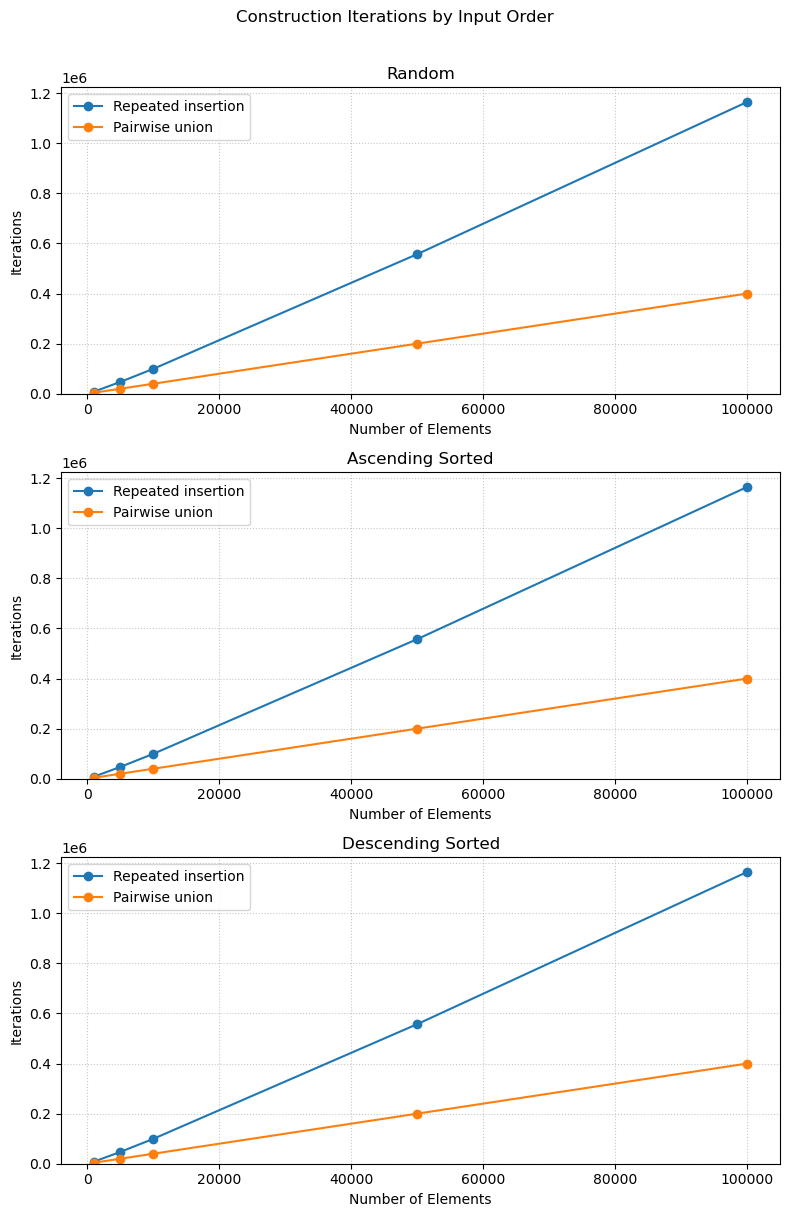

In [25]:
fig, axes = plt.subplots(3, 1, figsize=(8, 12))
for ax, order_name in zip(axes, ORDERS):
    subset = construction_df[construction_df["Input Order"] == order_name]
    ax.plot(subset["Elements"], subset["Insertion Iterations"], marker="o", label="Repeated insertion")
    ax.plot(subset["Elements"], subset["Pairwise Union Iterations"], marker="o", label="Pairwise union")
    ax.set_title(order_name)
    ax.set_xlabel("Number of Elements")
    ax.set_ylabel("Iterations")
    ax.set_ylim(bottom=0)
    ax.grid(True, linestyle=":", alpha=0.7)
    ax.legend()
fig.suptitle("Construction Iterations by Input Order", y=1.01)
plt.tight_layout()
plt.savefig("./2650026_lab10_data/construction_iterations.png", dpi=150, bbox_inches="tight")
plt.show()

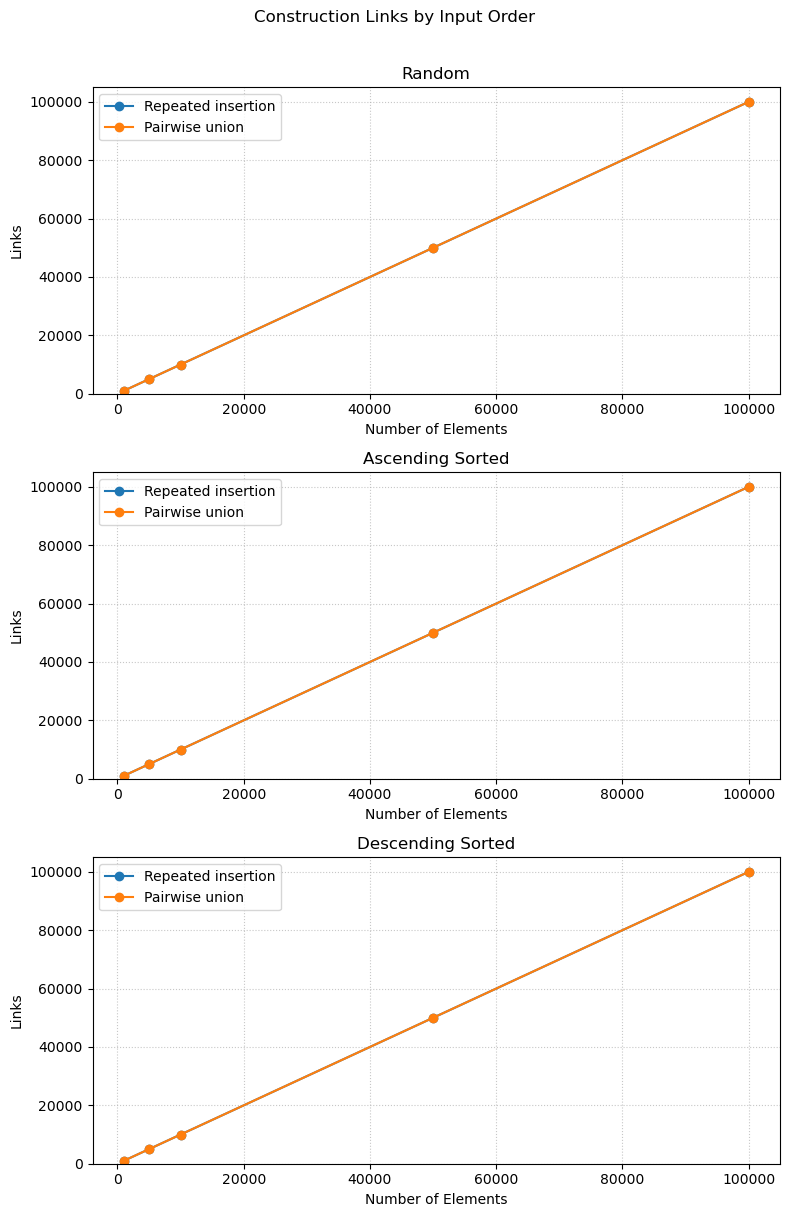

In [26]:
fig, axes = plt.subplots(3, 1, figsize=(8, 12))
for ax, order_name in zip(axes, ORDERS):
    subset = construction_df[construction_df["Input Order"] == order_name]
    ax.plot(subset["Elements"], subset["Insertion Links"], marker="o", label="Repeated insertion")
    ax.plot(subset["Elements"], subset["Pairwise Union Links"], marker="o", label="Pairwise union")
    ax.set_title(order_name)
    ax.set_xlabel("Number of Elements")
    ax.set_ylabel("Links")
    ax.set_ylim(bottom=0)
    ax.grid(True, linestyle=":", alpha=0.7)
    ax.legend()
fig.suptitle("Construction Links by Input Order", y=1.01)
plt.tight_layout()
plt.savefig("./2650026_lab10_data/construction_links.png", dpi=150, bbox_inches="tight")
plt.show()

### Cost of every single insertion

The graphs show the cost of every single insertion of the repeated insertion, and the number of trees after it, recorded for every heap size from 1 to 100000.

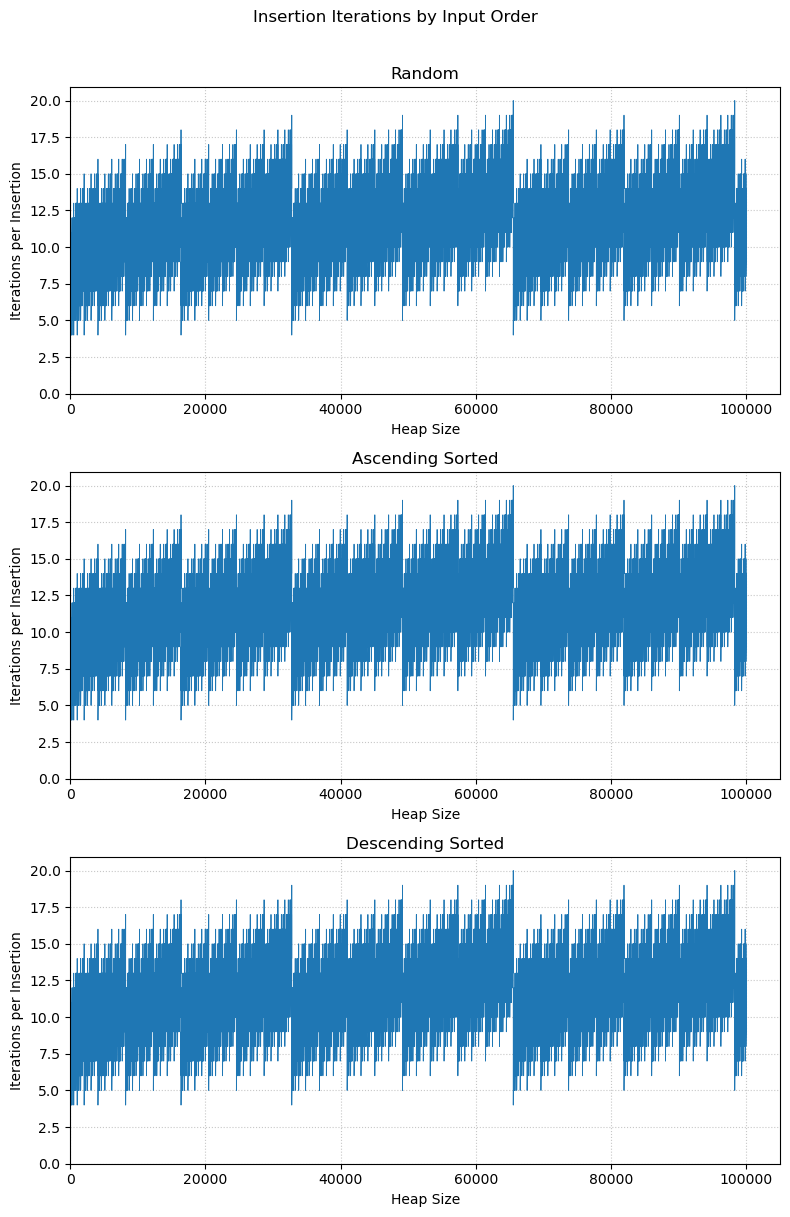

In [27]:
fig, axes = plt.subplots(3, 1, figsize=(8, 12))
for ax, order_name in zip(axes, ORDERS):
    y = records[(order_name, "Insertion")]["Iterations"]
    x = [i+1 for i in range(len(y))]
    ax.plot(x, y, linewidth=0.6)
    ax.set_title(order_name)
    ax.set_xlabel("Heap Size")
    ax.set_ylabel("Iterations per Insertion")
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)
    ax.grid(True, linestyle=":", alpha=0.7)
fig.suptitle("Insertion Iterations by Input Order", y=1.01)
plt.tight_layout()
plt.savefig("./2650026_lab10_data/insertion_iterations.png", dpi=150, bbox_inches="tight")
plt.show()

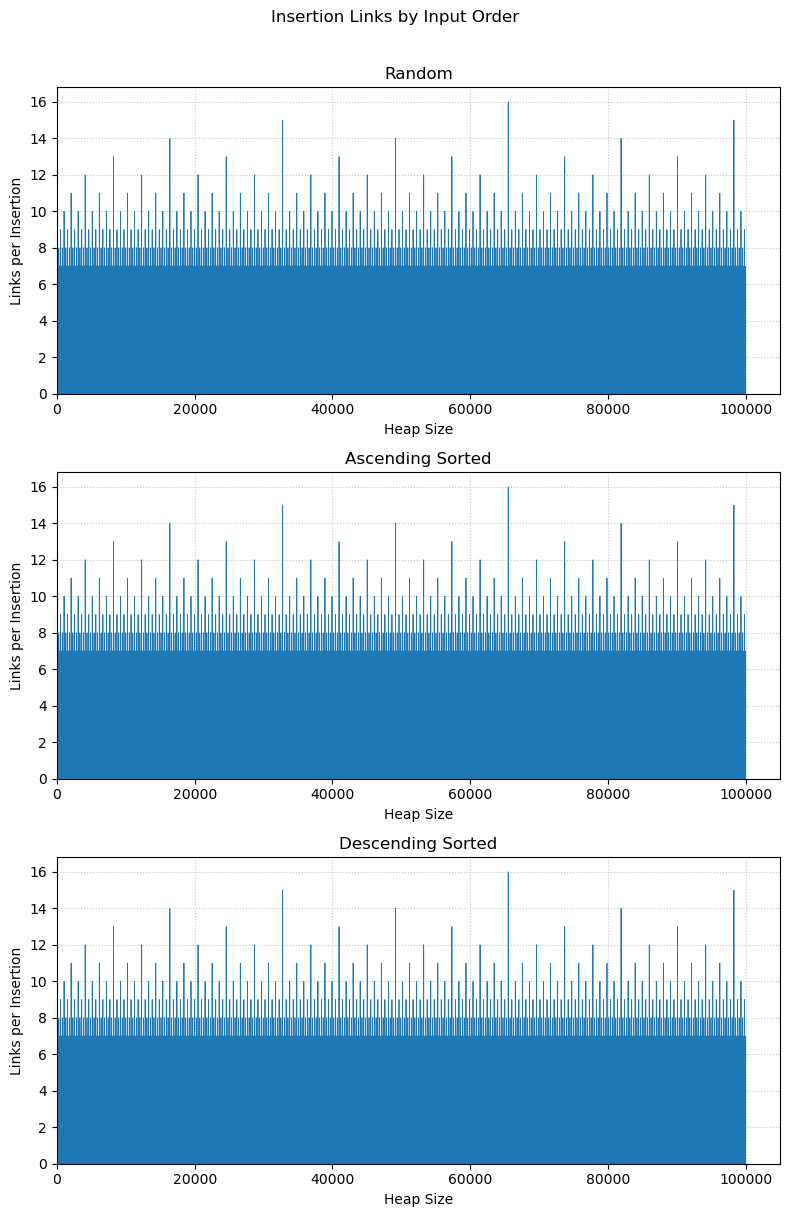

In [28]:
fig, axes = plt.subplots(3, 1, figsize=(8, 12))
for ax, order_name in zip(axes, ORDERS):
    y = records[(order_name, "Insertion")]["Links"]
    x = [i+1 for i in range(len(y))]
    ax.plot(x, y, linewidth=0.6)
    ax.set_title(order_name)
    ax.set_xlabel("Heap Size")
    ax.set_ylabel("Links per Insertion")
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)
    ax.grid(True, linestyle=":", alpha=0.7)
fig.suptitle("Insertion Links by Input Order", y=1.01)
plt.tight_layout()
plt.savefig("./2650026_lab10_data/insertion_links.png", dpi=150, bbox_inches="tight")
plt.show()

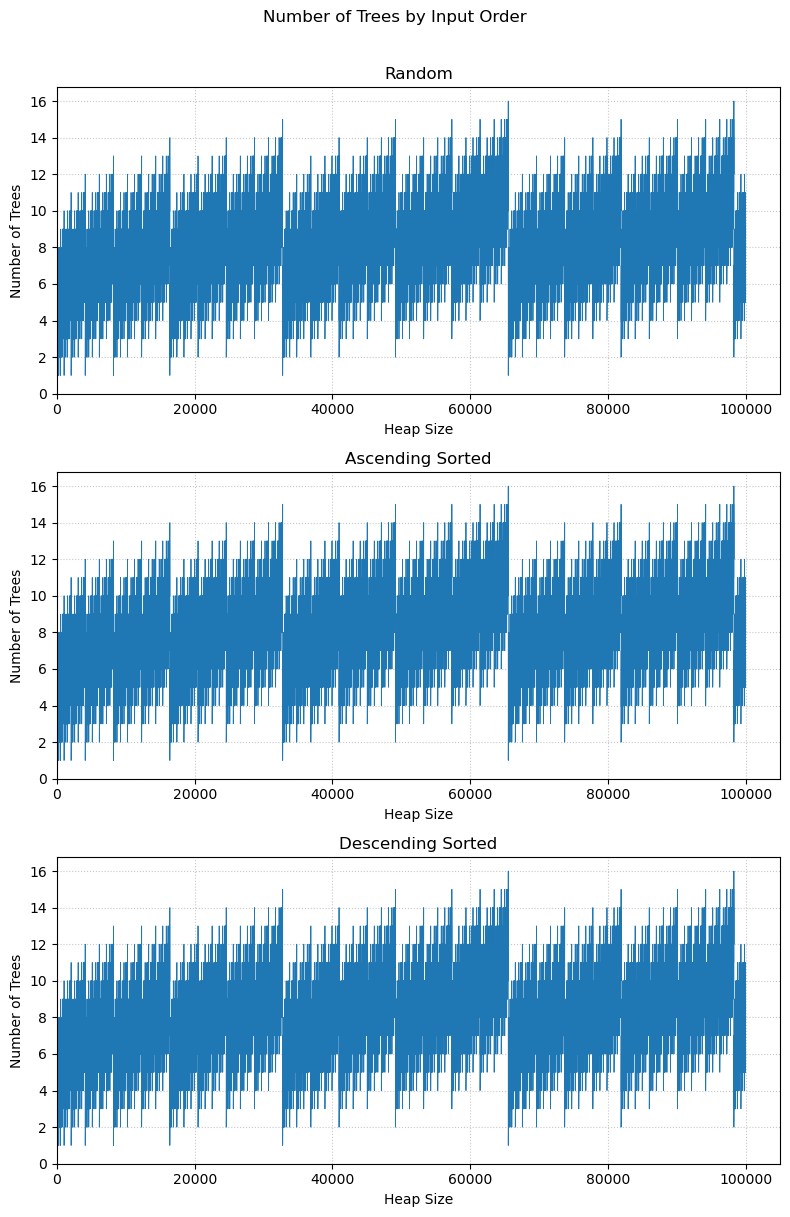

In [29]:
fig, axes = plt.subplots(3, 1, figsize=(8, 12))
for ax, order_name in zip(axes, ORDERS):
    y = records[(order_name, "Insertion")]["Trees"]
    x = [i+1 for i in range(len(y))]
    ax.plot(x, y, linewidth=0.6)
    ax.set_title(order_name)
    ax.set_xlabel("Heap Size")
    ax.set_ylabel("Number of Trees")
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)
    ax.grid(True, linestyle=":", alpha=0.7)
fig.suptitle("Number of Trees by Input Order", y=1.01)
plt.tight_layout()
plt.savefig("./2650026_lab10_data/insertion_trees.png", dpi=150, bbox_inches="tight")
plt.show()

### Save to CSV

In [30]:
construction_df.to_csv("./2650026_lab10_data/construction_summary.csv", index=False)

# The series plotted in the three graphs above, one row per input order and heap size
insertion_graph_df = pd.DataFrame([
    {"Input Order": order_name, "Heap Size": i+1,
     "Iterations per Insertion": records[(order_name, "Insertion")]["Iterations"][i],
     "Links per Insertion": records[(order_name, "Insertion")]["Links"][i],
     "Trees": records[(order_name, "Insertion")]["Trees"][i]}
    for order_name in ORDERS for i in range(N)
])
insertion_graph_df.to_csv("./2650026_lab10_data/insertion_graph_data.csv", index=False)

## Repeated Extract-Min Operations

The table holds the total cost of extracting all the elements of the size; the graphs show the cost of every single extract-min against the size of the heap it was performed on.

In [31]:
extract_df

,Elements,Input Order,Total Iterations,Total Links,Average Iterations per Extract-Min,Average Links per Extract-Min
0,1000,Random,38628,6442,38.62800,6.44200
1,1000,Ascending Sorted,14431,161,14.43100,0.16100
2,1000,Descending Sorted,13813,0,13.81300,0.00000
3,5000,Random,246760,43787,49.35200,8.75740
4,5000,Ascending Sorted,82171,678,16.43420,0.13560
5,5000,Descending Sorted,79525,0,15.90500,0.00000
6,10000,Random,543470,97602,54.34700,9.76020
7,10000,Ascending Sorted,171766,678,17.17660,0.06780
8,10000,Descending Sorted,169120,0,16.91200,0.00000
9,50000,Random,3306849,603282,66.13698,12.06564


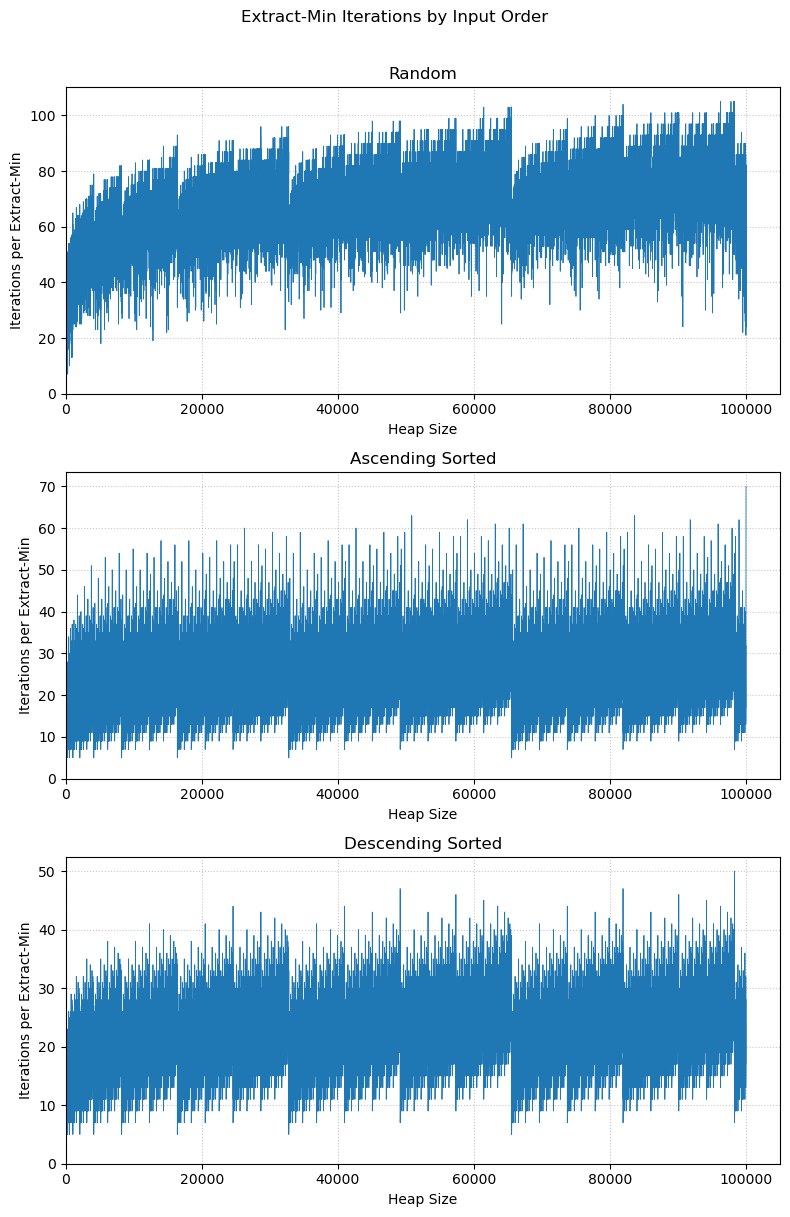

In [32]:
fig, axes = plt.subplots(3, 1, figsize=(8, 12))
for ax, order_name in zip(axes, ORDERS):
    y = records[(order_name, "Extract-Min")]["Iterations"]
    x = [i+1 for i in range(len(y))]
    ax.plot(x, y, linewidth=0.6)
    ax.set_title(order_name)
    ax.set_xlabel("Heap Size")
    ax.set_ylabel("Iterations per Extract-Min")
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)
    ax.grid(True, linestyle=":", alpha=0.7)
fig.suptitle("Extract-Min Iterations by Input Order", y=1.01)
plt.tight_layout()
plt.savefig("./2650026_lab10_data/extract_min_iterations.png", dpi=150, bbox_inches="tight")
plt.show()

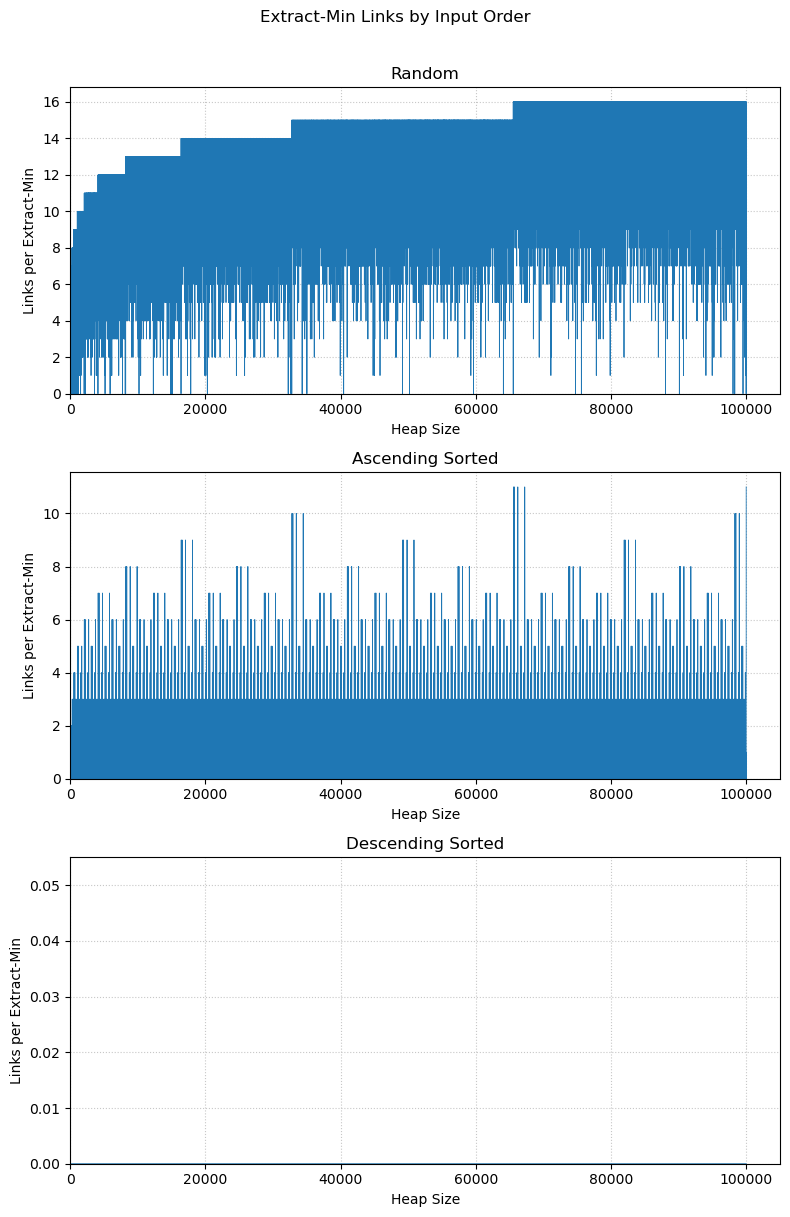

In [33]:
fig, axes = plt.subplots(3, 1, figsize=(8, 12))
for ax, order_name in zip(axes, ORDERS):
    y = records[(order_name, "Extract-Min")]["Links"]
    x = [i+1 for i in range(len(y))]
    ax.plot(x, y, linewidth=0.6)
    ax.set_title(order_name)
    ax.set_xlabel("Heap Size")
    ax.set_ylabel("Links per Extract-Min")
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)
    ax.grid(True, linestyle=":", alpha=0.7)
fig.suptitle("Extract-Min Links by Input Order", y=1.01)
plt.tight_layout()
plt.savefig("./2650026_lab10_data/extract_min_links.png", dpi=150, bbox_inches="tight")
plt.show()

### Save to CSV

In [34]:
extract_df.to_csv("./2650026_lab10_data/extract_min_summary.csv", index=False)

# The series plotted in the two graphs above, one row per input order and heap size
extract_graph_df = pd.DataFrame([
    {"Input Order": order_name, "Heap Size": i+1,
     "Iterations per Extract-Min": records[(order_name, "Extract-Min")]["Iterations"][i],
     "Links per Extract-Min": records[(order_name, "Extract-Min")]["Links"][i]}
    for order_name in ORDERS for i in range(N)
])
extract_graph_df.to_csv("./2650026_lab10_data/extract_min_graph_data.csv", index=False)

## Union of Two Heaps of N/2 Elements

Binomial heaps are united by merging the root lists and linking equal degrees; two binary heaps are united by concatenating the arrays and rebuilding the heap bottom-up (the Lab 7 and 8 code).

In [35]:
union_df

,Elements,Input Order,Binomial Union Iterations,Binomial Union Links,Binary Union Iterations,Binary Union Swaps,Trees of Heap 1,Trees of Heap 2,Trees After Union
0,1000,Random,24,6,885,385,6,6,6
1,1000,Ascending Sorted,24,6,500,0,6,6,6
2,1000,Descending Sorted,24,6,1417,917,6,6,6
3,5000,Random,20,5,4495,1995,5,5,5
4,5000,Ascending Sorted,20,5,2500,0,5,5,5
5,5000,Descending Sorted,20,5,7144,4644,5,5,5
6,10000,Random,20,5,8493,3493,5,5,5
7,10000,Ascending Sorted,20,5,5000,0,5,5,5
8,10000,Descending Sorted,20,5,14377,9377,5,5,5
9,50000,Random,24,6,39030,14030,6,6,6


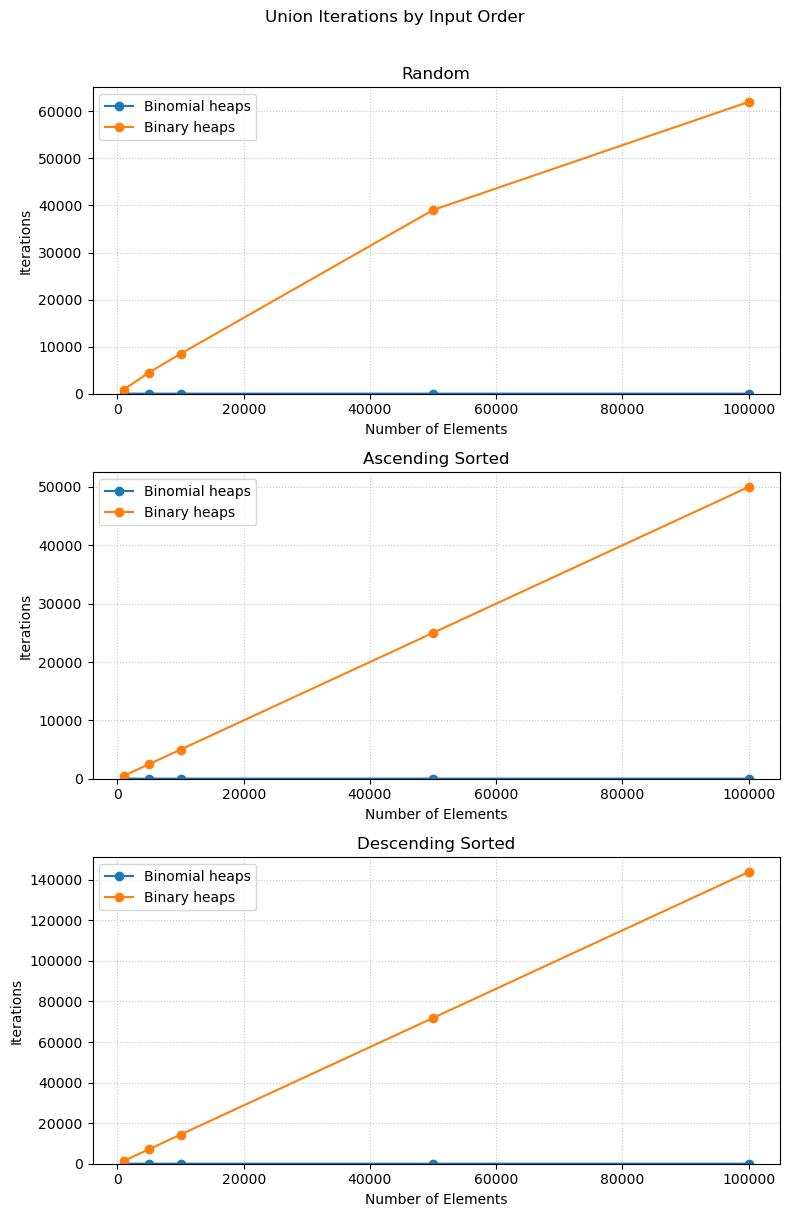

In [36]:
fig, axes = plt.subplots(3, 1, figsize=(8, 12))
for ax, order_name in zip(axes, ORDERS):
    subset = union_df[union_df["Input Order"] == order_name]
    ax.plot(subset["Elements"], subset["Binomial Union Iterations"], marker="o", label="Binomial heaps")
    ax.plot(subset["Elements"], subset["Binary Union Iterations"], marker="o", label="Binary heaps")
    ax.set_title(order_name)
    ax.set_xlabel("Number of Elements")
    ax.set_ylabel("Iterations")
    ax.set_ylim(bottom=0)
    ax.grid(True, linestyle=":", alpha=0.7)
    ax.legend()
fig.suptitle("Union Iterations by Input Order", y=1.01)
plt.tight_layout()
plt.savefig("./2650026_lab10_data/union_iterations.png", dpi=150, bbox_inches="tight")
plt.show()

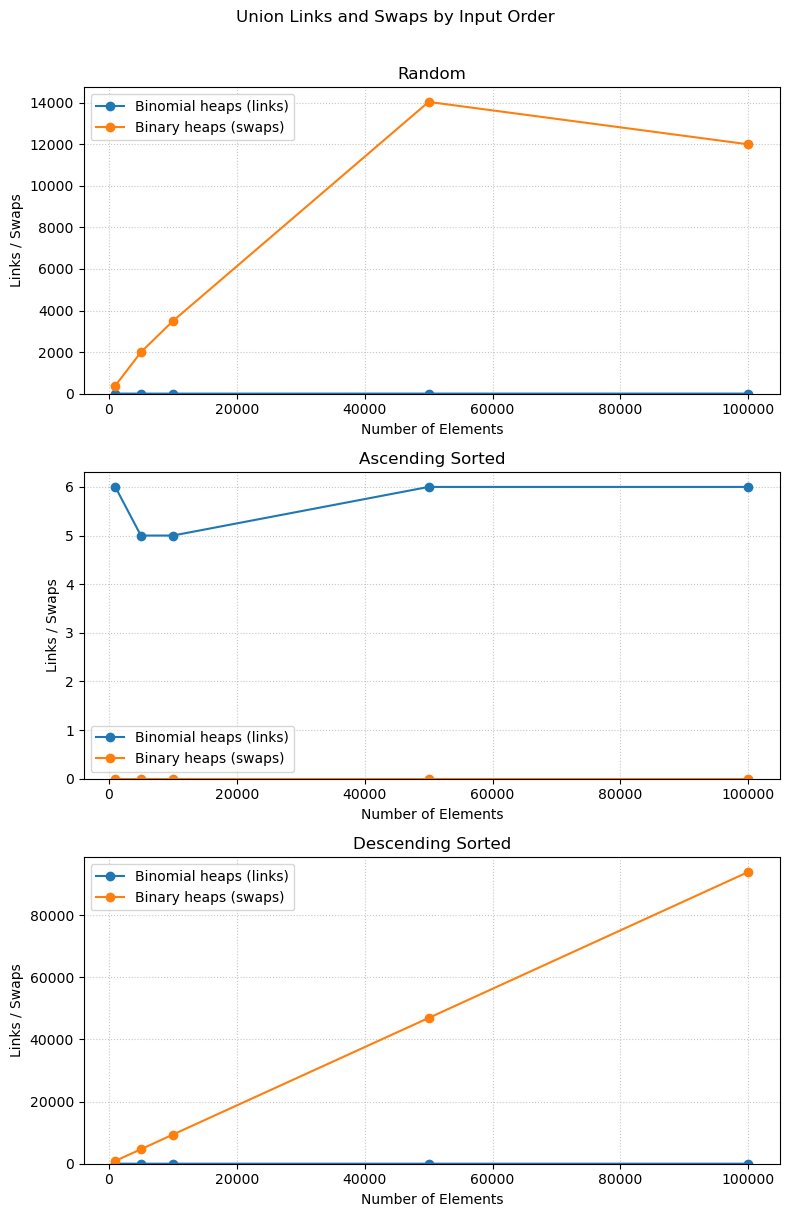

In [37]:
fig, axes = plt.subplots(3, 1, figsize=(8, 12))
for ax, order_name in zip(axes, ORDERS):
    subset = union_df[union_df["Input Order"] == order_name]
    ax.plot(subset["Elements"], subset["Binomial Union Links"], marker="o", label="Binomial heaps (links)")
    ax.plot(subset["Elements"], subset["Binary Union Swaps"], marker="o", label="Binary heaps (swaps)")
    ax.set_title(order_name)
    ax.set_xlabel("Number of Elements")
    ax.set_ylabel("Links / Swaps")
    ax.set_ylim(bottom=0)
    ax.grid(True, linestyle=":", alpha=0.7)
    ax.legend()
fig.suptitle("Union Links and Swaps by Input Order", y=1.01)
plt.tight_layout()
plt.savefig("./2650026_lab10_data/union_links_swaps.png", dpi=150, bbox_inches="tight")
plt.show()

### Save to CSV

In [38]:
union_df.to_csv("./2650026_lab10_data/union_summary.csv", index=False)

## Searching for an Existing and a Non-Existing Element

Every value is the mean over 100 keys (existing keys are drawn from the input, non-existing keys are values below the maximum that are not in the input). Searching neither links nor swaps.

In [39]:
search_df

,Elements,Input Order,Existing Average Iterations,Non-Existing Average Iterations
0,1000,Random,387.18,793.99
1,1000,Ascending Sorted,11.96,524.63
2,1000,Descending Sorted,334.34,521.59
3,5000,Random,2082.13,3628.74
4,5000,Ascending Sorted,15.09,2377.81
5,5000,Descending Sorted,811.82,2374.31
6,10000,Random,3694.01,7694.60
7,10000,Ascending Sorted,16.08,5585.92
8,10000,Descending Sorted,1538.43,5582.86
9,50000,Random,17654.08,42059.88


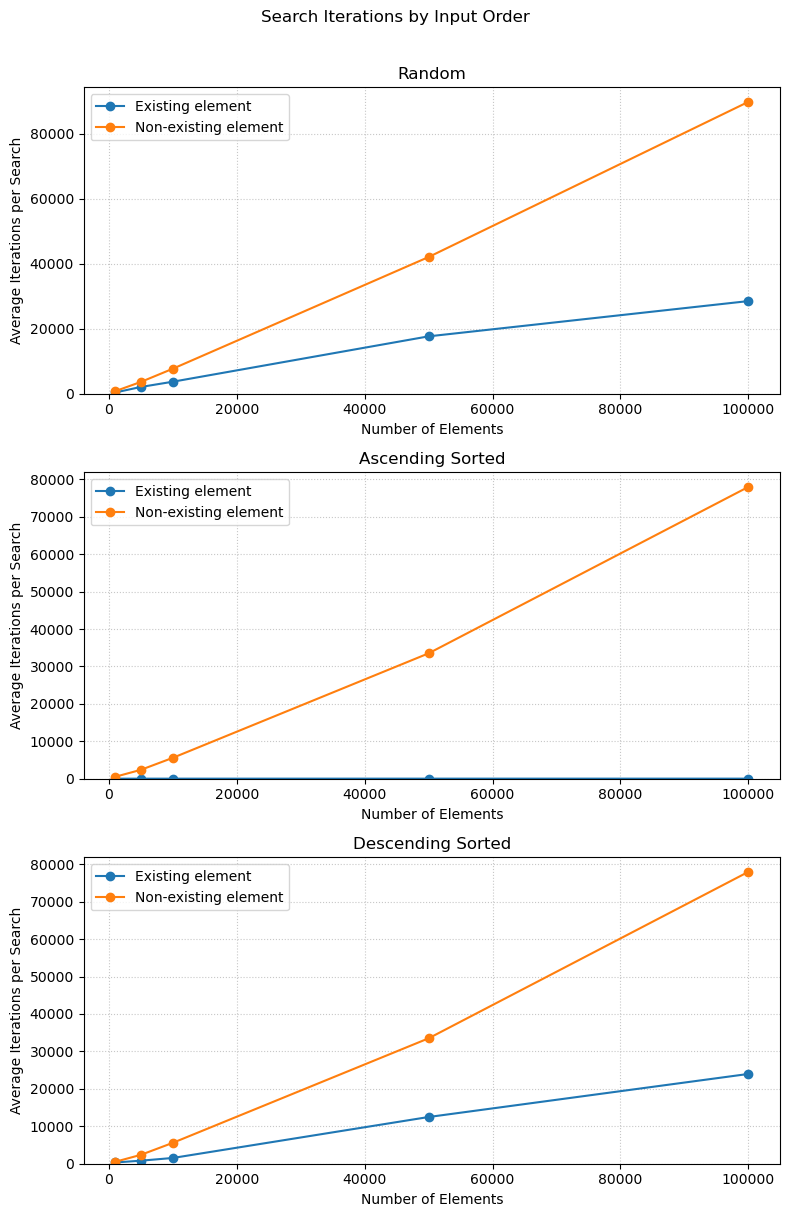

In [40]:
fig, axes = plt.subplots(3, 1, figsize=(8, 12))
for ax, order_name in zip(axes, ORDERS):
    subset = search_df[search_df["Input Order"] == order_name]
    ax.plot(subset["Elements"], subset["Existing Average Iterations"], marker="o", label="Existing element")
    ax.plot(subset["Elements"], subset["Non-Existing Average Iterations"], marker="o", label="Non-existing element")
    ax.set_title(order_name)
    ax.set_xlabel("Number of Elements")
    ax.set_ylabel("Average Iterations per Search")
    ax.set_ylim(bottom=0)
    ax.grid(True, linestyle=":", alpha=0.7)
    ax.legend()
fig.suptitle("Search Iterations by Input Order", y=1.01)
plt.tight_layout()
plt.savefig("./2650026_lab10_data/search_iterations.png", dpi=150, bbox_inches="tight")
plt.show()

### Save to CSV

In [41]:
search_df.to_csv("./2650026_lab10_data/search_summary.csv", index=False)